**Import Necessary Libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

**Load the Data**

In [ ]:
cats = np.load("../data/raw/cat.npy")
clocks = np.load("../data/raw/clock.npy")

**Data Description**

In [ ]:
print("Cats:", cats.shape)
print("Clocks:", clocks.shape)
print("Pix range:", cats.min(), cats.max())

Cats: (123202, 784)
Clocks: (120536, 784)
Pix range: 0 255


**Inspect a few samples**

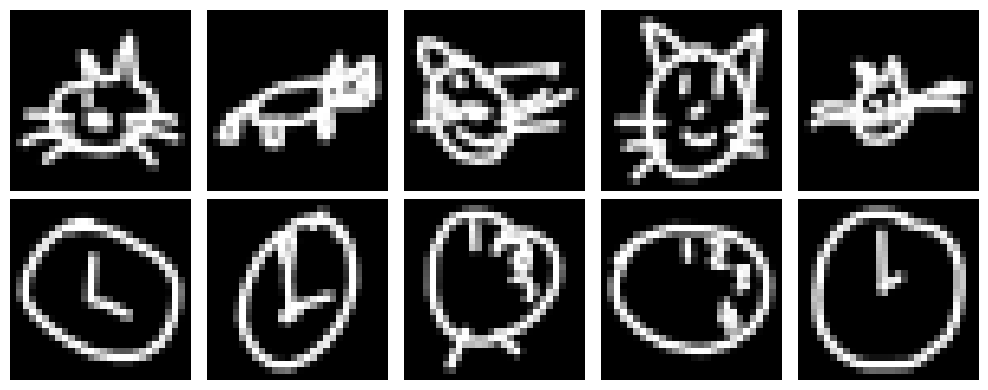

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(10, 4))
for i in range(5):
    axes[0, i].imshow(cats[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(clocks[i].reshape(28, 28), cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Cats")
axes[1, 0].set_ylabel("Clocks")
plt.tight_layout()
plt.show()

**Working with Subset + Combining Categories**
- 0 = cat
- 1 = clock

In [ ]:
np.random.seed(23)
n_per_class = 5000
cats = cats[np.random.choice(len(cats), n_per_class, replace=False)]
clocks = clocks[np.random.choice(len(clocks), n_per_class, replace=False)]

X = np.concatenate([cats, clocks], axis=0)
y = np.concatenate([
    np.zeros(len(cats), dtype=np.int64), #0=cat
    np.ones(len(clocks), dtype=np.int64) #1 = clocks 
])

**Normalize and reshape**

In [ ]:
#convert pix calues [0,255] --> [0,1]
X = X.astype(np.float32)/ 255.0

#reshape into (samples, channels, height, width)
X = X.reshape(-1, 1, 28, 28)

#shuffle images and labels together
rng = np.random.default_rng(42)
indices = rng.permutation(len(X))
X = X[indices]
y = y[indices]

# Checking normalization + reshaping 
print("Images (preprocessed):", X.shape)
print("Labels (preprocessed):", y.shape)
print("Pixel range (preprocessed):", X.min(), X.max())

Images (preprocessed): (10000, 1, 28, 28)
Labels (preprocessed): (10000,)
Pixel range (preprocessed): 0.0 1.0


**Saving processed data**

In [ ]:
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

#save X and y under named keys
np.savez_compressed(processed_dir / "quickdraw_dataset.npz", X=X, y=y)

**Split data**

In [ ]:
from sklearn.model_selection import train_test_split

# split into 70% train, 15% val, 15% test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42)

# save splits
np.savez_compressed(processed_dir / "quickdraw_splits.npz", 
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)

---
**VAE Architecture and Custom Loss**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim
        
        # Gaussian Encoder
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        
        # Bernoulli Decoder 
        self.fc3 = nn.Linear(latent_dim, 256)
        self.fc4 = nn.Linear(256, 512)
        self.fc5 = nn.Linear(512, 28 * 28)

    def encode(self, x):
        h = F.relu(self.fc1(x.view(-1, 28 * 28)))
        h = F.relu(self.fc2(h))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = F.relu(self.fc3(z))
        h = F.relu(self.fc4(h))
        # sigmoid activ to output [0,1] range for bernoulli dist
        return torch.sigmoid(self.fc5(h)).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar

def elbo_loss(recon_x, x, mu, logvar, beta=1.0):
    # Reconstruction Loss (binary cross entropy for bernoulli)
    BCE = F.binary_cross_entropy(recon_x.view(-1, 28*28), x.view(-1, 28*28), reduction='sum')
    
    # KL divergence to std normal prior
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    # : total loss with individual components for tracking
    return BCE + beta * KLD, BCE, KLD

**Interpolation Utilities, Baselines**

In [ ]:
def lerp(z1, z2, steps=10):
    """linear interpolation btwn two latent vectors"""
    alphas = torch.linspace(0, 1, steps).view(-1, 1).to(z1.device)
    return (1 - alphas) * z1 + alphas * z2

def slerp(z1, z2, steps=10):
    """spherical linear interpolation btwn two latent vectors."""
    alphas = torch.linspace(0, 1, steps).view(-1, 1).to(z1.device)
    
    z1_norm = z1 / torch.norm(z1)
    z2_norm = z2 / torch.norm(z2)
    omega = torch.acos(torch.clamp(torch.sum(z1_norm * z2_norm), -1.0, 1.0))
    so = torch.sin(omega)
    
    if so == 0:
        return lerp(z1, z2, steps) # fall back to lerp if vectors are colinear
    
    return torch.sin((1.0 - alphas) * omega) / so * z1 + torch.sin(alphas * omega) / so * z2

def pixel_crossfade(x1, x2, steps=10):
    """No-learning baseline: pixel space crossfade"""
    alphas = torch.linspace(0, 1, steps).view(-1, 1, 1, 1).to(x1.device)
    return (1 - alphas) * x1 + alphas * x2

**Evaluation metrics pipeline**

In [ ]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

def calculate_realism(interpolated_codes, training_codes):
    """Adapting Kynkäänniemi et al. (2019) nearest neighbor realism metric."""
    # get usual spacing btwn training points
    nn_train = NearestNeighbors(n_neighbors=2).fit(training_codes)
    distances, _ = nn_train.kneighbors(training_codes)
    typical_spacing = np.median(distances[:, 1])
    
    # Calculate distance from interpolated points to nearest training point
    nn_interp = NearestNeighbors(n_neighbors=1).fit(training_codes)
    distances_to_real, _ = nn_interp.kneighbors(interpolated_codes)
    
    # Near or below 1 = stays close to real data
    return (distances_to_real / typical_spacing).mean()

def calculate_smoothness(interpolated_images):
    """Adapting Karras et al. (2019) PPL using pixel L2 distance."""
    # calc L2 dist btwn consecutive generated frames
    diffs = torch.sqrt(torch.sum((interpolated_images[1:] - interpolated_images[:-1])**2, dim=(1,2,3)))
    
    # largest step relative to average (near 1 ==> no sudden jumps)
    return diffs.max().item() / (diffs.mean().item() + 1e-8)

# indep CNN classifier for semantic change (track P(clock))
class CatClockClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc = nn.Linear(16 * 14 * 14, 1)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))
        x = x.view(-1, 16 * 14 * 14)
        return torch.sigmoid(self.fc(x)) # ==> probability of being a clock